# SVM, RANDOM FOREST AND ADABOOST

## IMPORTING LIBRARIES

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import OrdinalEncoder, LabelEncoder
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

#### LOADING DATASET

In [2]:
columns = ["buying_price", "maintenance_cost", "number_of_doors", "number_of_persons", "lug_boot", "safety", "decision"]
df = pd.read_csv("car_evaluation.csv", header=None, names=columns)

print("Number of samples:", df.shape[0])
print("Number of features:", df.shape[1])
df.head(5)

Number of samples: 1728
Number of features: 7


,buying_price,maintenance_cost,number_of_doors,number_of_persons,lug_boot,safety,decision
0,vhigh,vhigh,2,2,small,low,unacc
1,vhigh,vhigh,2,2,small,med,unacc
2,vhigh,vhigh,2,2,small,high,unacc
3,vhigh,vhigh,2,2,med,low,unacc
4,vhigh,vhigh,2,2,med,med,unacc


#### DATA ANALYSIS

In [3]:
print("Missing values:")
print(df.isnull().sum())

duplicates = df.duplicated().sum()
print("\nNo duplicate rows present." if duplicates == 0 else f"\nDuplicate rows: {duplicates}")

Missing values:
buying_price         0
maintenance_cost     0
number_of_doors      0
number_of_persons    0
lug_boot             0
safety               0
decision             0
dtype: int64

No duplicate rows present.


In [4]:
print("\nUnique values in each column:")
for column in df.columns:
    print(column, ":", df[column].unique())


Unique values in each column:
buying_price : <ArrowStringArray>
['vhigh', 'high', 'med', 'low']
Length: 4, dtype: str
maintenance_cost : <ArrowStringArray>
['vhigh', 'high', 'med', 'low']
Length: 4, dtype: str
number_of_doors : <ArrowStringArray>
['2', '3', '4', '5more']
Length: 4, dtype: str
number_of_persons : <ArrowStringArray>
['2', '4', 'more']
Length: 3, dtype: str
lug_boot : <ArrowStringArray>
['small', 'med', 'big']
Length: 3, dtype: str
safety : <ArrowStringArray>
['low', 'med', 'high']
Length: 3, dtype: str
decision : <ArrowStringArray>
['unacc', 'acc', 'vgood', 'good']
Length: 4, dtype: str


In [5]:
print("\nDecision class distribution:")
print(df["decision"].value_counts())


Decision class distribution:
decision
unacc    1210
acc       384
good       69
vgood      65
Name: count, dtype: int64


In [8]:
X = df.drop(columns=["decision"])
y = df["decision"]

#### ONEHOT ENCODING AND LABEL ENCODER

In [9]:
X = OrdinalEncoder().fit_transform(X)
encoder = LabelEncoder()
y = encoder.fit_transform(y)

print("Encoded X:")
display(pd.DataFrame(X).head(10))
print(encoder.classes_)

Encoded X:


,0,1,2,3,4,5
0,3.0,3.0,0.0,0.0,2.0,1.0
1,3.0,3.0,0.0,0.0,2.0,2.0
2,3.0,3.0,0.0,0.0,2.0,0.0
3,3.0,3.0,0.0,0.0,1.0,1.0
4,3.0,3.0,0.0,0.0,1.0,2.0
5,3.0,3.0,0.0,0.0,1.0,0.0
6,3.0,3.0,0.0,0.0,0.0,1.0
7,3.0,3.0,0.0,0.0,0.0,2.0
8,3.0,3.0,0.0,0.0,0.0,0.0
9,3.0,3.0,0.0,1.0,2.0,1.0


['acc' 'good' 'unacc' 'vgood']


#### MODEL TRAINING

In [10]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [ ]:
models = {"SVM": SVC(), "Random Forest": RandomForestClassifier(), "AdaBoost": AdaBoostClassifier()}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    print("\n" + name)
    print("Training Accuracy:", accuracy_score(y_train, model.predict(X_train)))
    print("Testing Accuracy:", accuracy_score(y_test, y_pred))
    print(classification_report(y_test, y_pred, target_names=encoder.classes_))

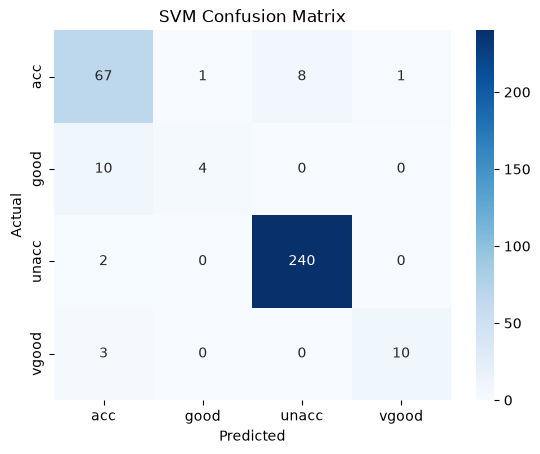

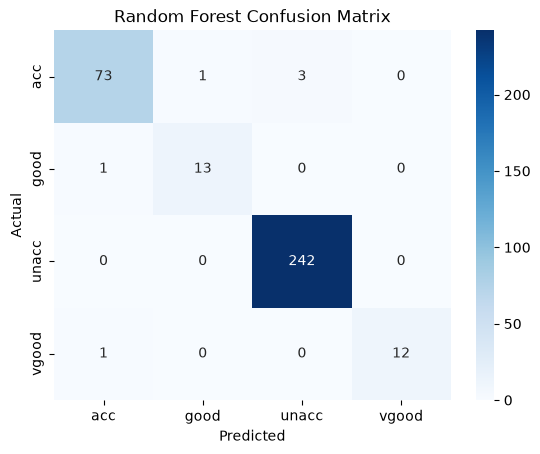

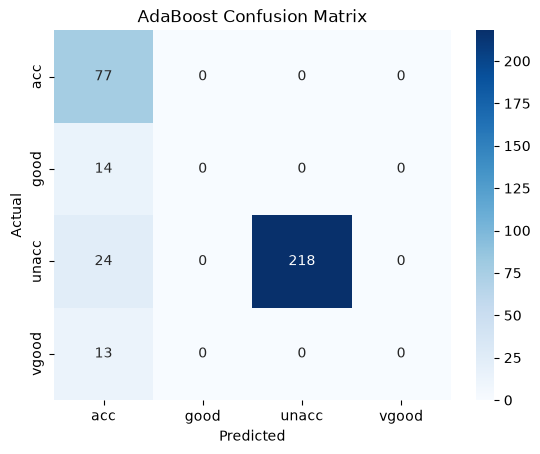

In [43]:
for name, model in models.items():
    sns.heatmap(confusion_matrix(y_test, model.predict(X_test)), annot=True, fmt="d", cmap="Blues",
                xticklabels=encoder.classes_, yticklabels=encoder.classes_)
    plt.title(f"{name} Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

In [17]:
for model in models.values():
    scores = cross_val_score(model, X_train, y_train, cv=5)
    print("Fold accuracies:", scores)
    print("Mean Accuracy:", f"{scores.mean():.2%}")
    print("Standard Deviation:", scores.std())

Fold accuracies: [0.90252708 0.89169675 0.87318841 0.88768116 0.88043478]
Mean Accuracy: 88.71%
Standard Deviation: 0.009974166136854248
Fold accuracies: [0.96750903 0.97833935 0.94927536 0.96376812 0.95652174]
Mean Accuracy: 96.31%
Standard Deviation: 0.009864241547308769
Fold accuracies: [0.84837545 0.84837545 0.85507246 0.8442029  0.86594203]
Mean Accuracy: 85.24%
Standard Deviation: 0.00761728124482765


#### HYPERPARAMETER TUNING

In [51]:
grids = {
    "SVM": (SVC(), {'C': [0.1, 1, 10], 'kernel': ['linear', 'rbf'], 'gamma': ['scale', 'auto']}),
    "Random Forest": (RandomForestClassifier(random_state=42),
                      {'n_estimators': [50, 100, 200], 'max_depth': [10, 20], 'min_samples_split': [2, 5]}),
    "AdaBoost": (AdaBoostClassifier(random_state=42),
                 {'n_estimators': [50, 100, 200], 'learning_rate': [0.01, 0.1, 1.0]}),
}

best = {}
for name, (model, params) in grids.items():
    grid = GridSearchCV(model, params, cv=5, scoring='accuracy', n_jobs=-1).fit(X_train, y_train)
    print("Best Parameters:", grid.best_params_)
    print("Best CV Accuracy:", f"{grid.best_score_:.2%}")
    best[name] = grid.best_estimator_

Best Parameters: {'C': 10, 'gamma': 'auto', 'kernel': 'rbf'}
Best CV Accuracy: 98.34%


Best Parameters: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200}
Best CV Accuracy: 96.45%


Best Parameters: {'learning_rate': 1.0, 'n_estimators': 100}
Best CV Accuracy: 85.53%


In [55]:
for name, model in best.items():
    y_pred = model.predict(X_test)
    print("\n", name)
    print("Accuracy:", f"{accuracy_score(y_test, y_pred):.2%}")
    for metric, func in [("Precision", precision_score), ("Recall", recall_score), ("F1 Score", f1_score)]:
        print(f"{metric}:", f"{func(y_test, y_pred, average='weighted', zero_division=0):.2%}")


 SVM
Accuracy: 99.13%
Precision: 99.14%
Recall: 99.13%
F1 Score: 99.13%

 Random Forest
Accuracy: 97.98%
Precision: 97.97%
Recall: 97.98%
F1 Score: 97.96%

 AdaBoost
Accuracy: 84.97%
Precision: 85.55%
Recall: 84.97%
F1 Score: 84.73%
